## Soveltava matematiikka ja fysiikka ohjelmoinnissa, harjoitukset 9.11.2026

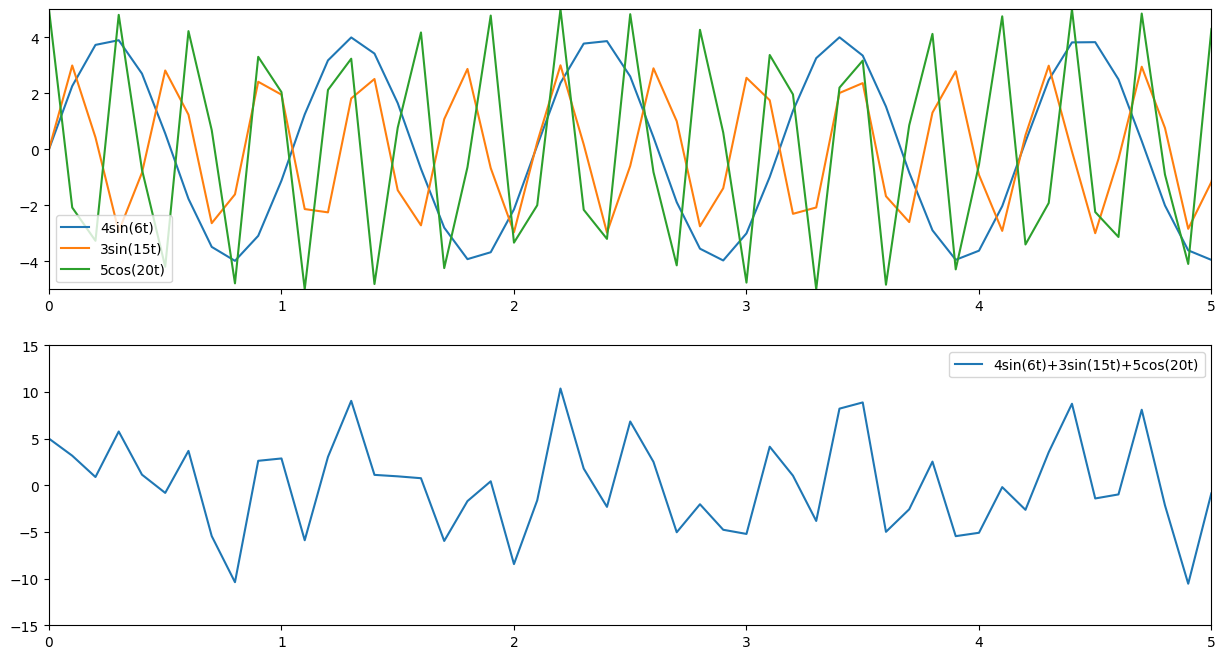

In [11]:
# Tehtävä 12
# Muodosta signaali

# s(t)=4sin(6t)+3sin(15t)+5cos(20t)
# näytteenottovälillä 0,1 s aikavälillä 0≤t<100 s.

# a) Piirrä osasignaalit ja niiden summa. Rajaa aika-akselia tarvittaessa.

import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 

dt = 0.1 #Näytteenottoväli
t = np.arange(0,100,dt) #Aika

s1 = 4*np.sin(6*t)
s2 = 3*np.sin(15*t)
s3 = 5*np.cos(20*t)
s = s1 + s2 + s3

#Piirretään kuva osasignaaleista s1, s2 ja s3, sekä summasignaalista
plt.figure(figsize = (15,8))
plt.subplot(2,1,1)
plt.plot(t,s1,label = '4sin(6t)')
plt.plot(t,s2,label = '3sin(15t)')
plt.plot(t,s3,label = '5cos(20t)')
plt.axis([0,5,-5,5])
plt.legend()
plt.subplot(2,1,2)
plt.plot(t,s, label = '4sin(6t)+3sin(15t)+5cos(20t)')
plt.legend()
plt.axis([0,5,-15,15])
plt.show()

#Huomataan, että summasignaalista on hyvin vaikeaa suoraan nähdä, mitä taajuuksia siinä on mukana. 

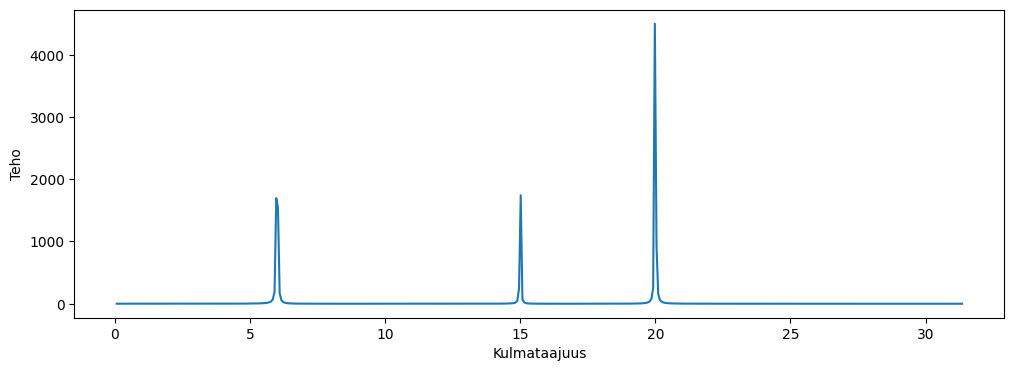

In [ ]:

#Dirichlet’n Fourier-lause: Jaksollinen signaali (funktio) voidaan esittää sini-ja kosimuotoisten signaalien (funktioiden summana)
#Eli käytännössä voidaan selvittää, miten summasignaali on rakentunut, vaikka meillä olisi tiedossa ainoastaan havaittu summasignaali. 

# b) Laske summan Fourier-muunnos FFT-algoritmilla ja sen tehospektri.
# Syntakseja on monenlaisia, mutta yritän tässä käyttää mahdollisimman havainnollista.
N = len(s) #Datapisteiden määrä
fourier = np.fft.fft(s,N) #Fourier-muunnos
#Kuvaa signaalin s taajuusavaruudessa. Käytännössä sisältää tarkan tiedon siitä, millaisista sini-ja kosifunktiosta s rakentuu. 

#Tehospektri kertoo, kuinka suuri on minkäkin signaalissa esiintyvän taajuuden teho. Se ei erottele sini- ja kosinikomponentteja
psd = fourier*np.conj(fourier)/N #Tehospektri

# c) Muodosta taajuusakseli hertseinä ja tunnista spektrin huiput.
freq = np.fft.fftfreq(N,dt) #Taajuudet, joita datasta voidaan havaita

#Rajataan pois negatiiviset taajuudet
#Muistetaan taajuuden ja kulmtaajuuden välinen yhteys: omega = 2*pi*f
#Muistetaan, että sini- ja kosifunktiot ovat muotoa sin(omega*t) ja cos(omega*t)
L = np.arange(1,np.floor(N/2),dtype = 'int')
plt.figure(figsize=(12,4))
#plt.plot(freq[L],psd[L].real)
#plt.xlabel('Taajuus')
plt.plot(2*np.pi*freq[L],psd[L].real)
plt.xlabel('Kulmataajuus')
plt.ylabel('Teho')
plt.show()

# d) Vertaa huippujen (kulma)taajuuksia alkuperäisten funktioiden kulmataajuuksiin.
#s(t)=4sin(6t)+3sin(15t)+5cos(20t)
# Huomataan, että alkuperäisen signaalin (kulma)taajuudet havaitaan selvästi piikkeinä tehospektrissä.

c:\Users\ilpovirt\AppData\Local\Programs\Python\Python312\Lib\site-packages\matplotlib\cbook.py:1762: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\ilpovirt\AppData\Local\Programs\Python\Python312\Lib\site-packages\matplotlib\cbook.py:1398: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


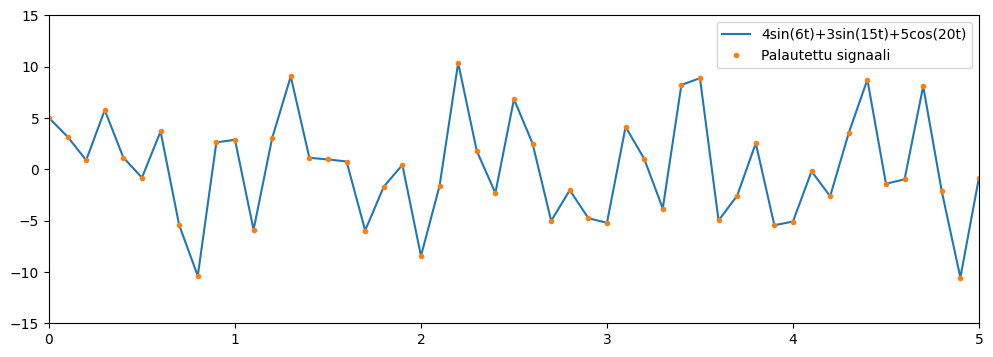

In [28]:
# e) Palauta signaali käänteismuunnoksella ja vertaa sitä alkuperäiseen.
s_pal = np.fft.ifft(fourier,N)

plt.figure(figsize=(12,4))
plt.plot(t,s, label = '4sin(6t)+3sin(15t)+5cos(20t)')
plt.plot(t,s_pal, ' .' ,label = 'Palautettu signaali')
plt.legend()
plt.axis([0,5,-15,15])
plt.show()

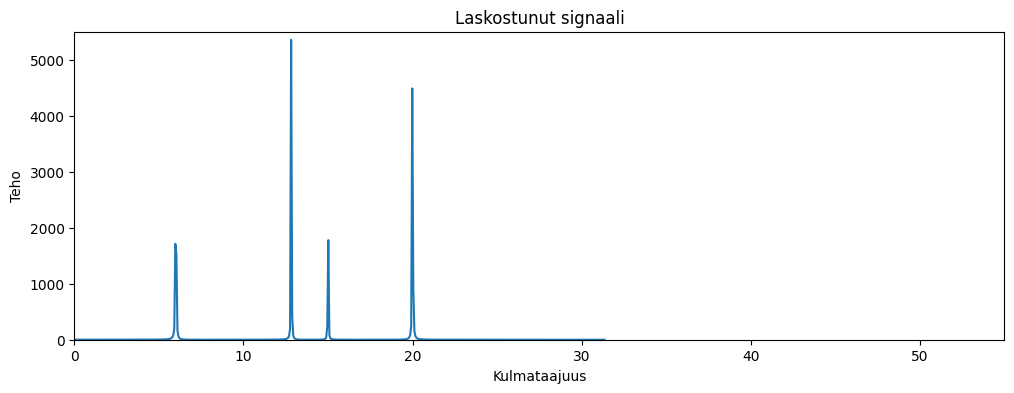

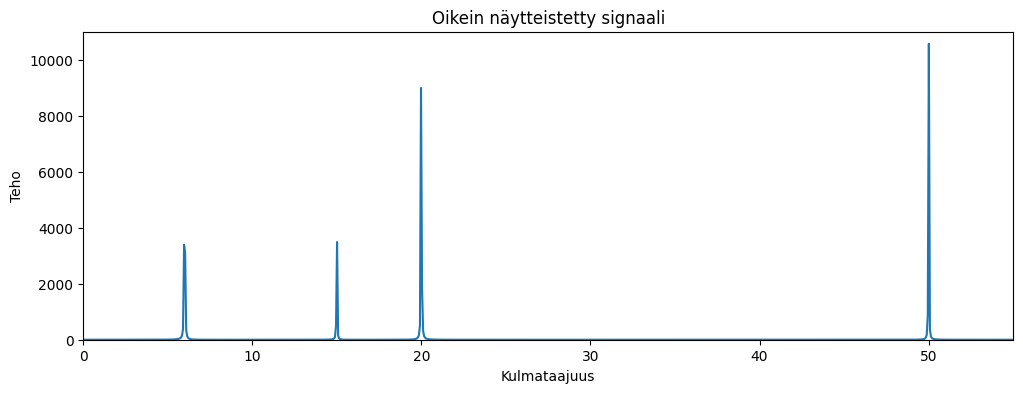

In [38]:
# Tehtävä 13
# Lisää tehtävän 12 signaaliin 5cos(50t).
# a) Tutki muutosta tehospektrissä käyttäen edelleen näytteenottoväliä 0,1 s.
# b) Selitä, miksi uusi huippu ei näy odotetulla taajuudella.
# c) Valitse riittävä näytteenottotaajuus ja tarkista tulos muodostamalla signaali ja laskemalla Fourier-muunnos uudelleen.

dt = 0.1
t = np.arange(0,100,dt)
s = 4*np.sin(6*t) + 3*np.sin(15*t) + 5*np.cos(20*t) + 5*np.cos(50*t)

#Fourier-muunnos ja tehospektri
N = len(s)
fourier = np.fft.fft(s,N)
psd = fourier*np.conj(fourier)/N
freq = np.fft.fftfreq(N,dt)
L = np.arange(1,np.floor(N/2),dtype = 'int')

plt.figure(figsize=(12,4))
plt.plot(2*np.pi*freq[L],psd[L].real)
plt.axis([0,55,0,5500])
plt.xlabel('Kulmataajuus')
plt.ylabel('Teho')
plt.title('Laskostunut signaali')
plt.show()

#Huomataan, että piikkiä ei näy 50 kulmataajuudella, vaan virheellinen piikki 13 paikkeilla. 
#Tämä on laskostumisen syytä:
#Näytteenottotaajuus on 10Hz, joten suurin taajuus joka voidaan havaita on 5Hz (Nyqvistin taajuus), jota vastaa kulmataajuus 5*2*pi = 31.4
#Nyqvistin taajuutta suuremmat taajuudet tulee suodattaa signaalista ennen näytteistystä. 
#Näytteenottotaajuutta voidaan nosta (jos mahdollista. )

dt = 0.05
t = np.arange(0,100,dt)
s = 4*np.sin(6*t) + 3*np.sin(15*t) + 5*np.cos(20*t) + 5*np.cos(50*t)

#Fourier-muunnos ja tehospektri
N = len(s)
fourier = np.fft.fft(s,N)
psd = fourier*np.conj(fourier)/N
freq = np.fft.fftfreq(N,dt)
L = np.arange(1,np.floor(N/2),dtype = 'int')

plt.figure(figsize=(12,4))
plt.plot(2*np.pi*freq[L],psd[L].real)
plt.axis([0,55,0,11000])
plt.xlabel('Kulmataajuus')
plt.ylabel('Teho')
plt.title('Oikein näytteistetty signaali')
plt.show()